# CSR global

In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [2]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

gbif_group <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group.csv")

head(gbif_group)

h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211


In [3]:
summary(gbif_group$X.X47)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.070   0.257   0.284   0.293   0.318   0.656 

In [4]:
library(data.table)

# ── StrateFy (Pierce et al. 2017) ─────────────────────────────────────────────
stratefy <- function(LA, LDMC, SLA) {
  # Units: LA mm², LDMC in %, SLA mm² mg⁻¹
  la_t   <- sqrt(LA / 894205) * 100
  ldmc_t <- log((LDMC / 100) / (1 - LDMC / 100))
  sla_t  <- log(SLA)

  c_raw <- -0.8678 + 1.6464 * la_t
  s_raw <- 1.3369 + 0.000010019 * (1 - exp(-0.0000000000022303 * ldmc_t)) +
           4.5835 * (1 - exp(-0.2328 * ldmc_t))
  r_raw <- -57.5924 + 62.6802 * exp(-0.0288 * sla_t)

  minC <- 0;                  maxC <- 57.3756711966087
  minS <- -0.756451214853076; maxS <- 5.79158377609218
  minR <- -11.3467682227961;  maxR <- 1.10795515716546

  c_raw <- pmin(pmax(c_raw, minC), maxC)
  s_raw <- pmin(pmax(s_raw, minS), maxS)
  r_raw <- pmin(pmax(r_raw, minR), maxR)

  pC <- (c_raw - minC) / (maxC - minC) * 100
  pS <- (s_raw - minS) / (maxS - minS) * 100
  pR <- 100 - (r_raw - minR) / (maxR - minR) * 100   # SLA loads negatively

  k <- 100 / (pC + pS + pR)
  list(C = pC * k, S = pS * k, R = pR * k)
}

# ── Apply to your data ────────────────────────────────────────────────────────

LA_COLS <- c("X.X3114", "X.X3113", "X.X3112")   # preferred order

# 1. Resolve LA first
gbif_group[, LA_resolved := fcoalesce(.SD), .SDcols = LA_COLS]

# 2. Check units before computing
summary(gbif_group[, .(LA_resolved, X.X47, X.X3117)])

# 3. Compute CSR (LDMC g/g → %)
gbif_group[, c("C", "S", "R") := stratefy(10^LA_resolved, X.X47 * 100, X.X3117)]

# 4. Summary
gbif_group[, .(C = mean(C, na.rm = TRUE),
               S = mean(S, na.rm = TRUE),
               R = mean(R, na.rm = TRUE)), by = group]

  LA_resolved        X.X47          X.X3117      
 Min.   :0.626   Min.   :0.070   Min.   : 3.143  
 1st Qu.:2.597   1st Qu.:0.257   1st Qu.:14.114  
 Median :2.867   Median :0.284   Median :17.274  
 Mean   :2.850   Mean   :0.293   Mean   :17.383  
 3rd Qu.:3.120   3rd Qu.:0.318   3rd Qu.:20.481  
 Max.   :4.731   Max.   :0.656   Max.   :58.834  

group,C,S,R
<chr>,<dbl>,<dbl>,<dbl>
all,23.57530,50.75085,25.67385
native,23.66794,52.14462,24.18744


In [5]:
head(gbif_group)

h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,LA_resolved,C,S,R
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,85.452,2.183,3.140,-0.547,0.3330000,0.152,1.449,0.9115658,0.00000,99.08843
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,85.452,2.183,3.140,-0.547,0.3330000,0.152,1.449,0.9115658,0.00000,99.08843
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,92.099,2.545,3.121,-0.563,0.3166111,0.175,1.518,2.9437334,19.72053,77.33574
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,92.099,2.545,3.121,-0.563,0.3291221,0.175,1.518,2.9437334,19.72053,77.33574
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,88.269,2.311,3.671,-1.933,0.4090000,0.211,1.391,0.0000000,47.80706,52.19294
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,88.269,2.311,3.671,-1.933,0.4090000,0.211,1.391,0.0000000,47.80706,52.19294


In [6]:
# save the updated data.table to a new CSV file
fwrite(gbif_group, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group_with_CSR.csv")

Installing package into ‘/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4’
(as ‘lib’ is unspecified)

Warning message in geom_point(data = group_means, aes(x = R, y = C, z = S, fill = group), :
“Ignoring unknown aesthetics: z”
Warning message in ggint$plot_theme(plot):
“The `tern.axis.title.size` theme element is not defined in the element
hierarchy.”
Warning message:
“Removed 640 rows containing non-finite outside the scale range
(`StatDensityTern()`).”
Warning message:
“stat_density_tern: You have not specified a below-detection-limit (bdl) value (Ref. 'bdl' and 'bdl.val' arguments in ?stat_density_tern). Presently you have 2x value/s below a detection limit of 0.001, which acounts for 0.022% of your data. Density values at fringes may appear abnormally high attributed to the mathematics of the ILR transformation. 
You can either:
1. Ignore this warning,
2. Set the bdl value appropriately so that fringe values are omitted from the ILR calculation, or
3. Accept the high density value

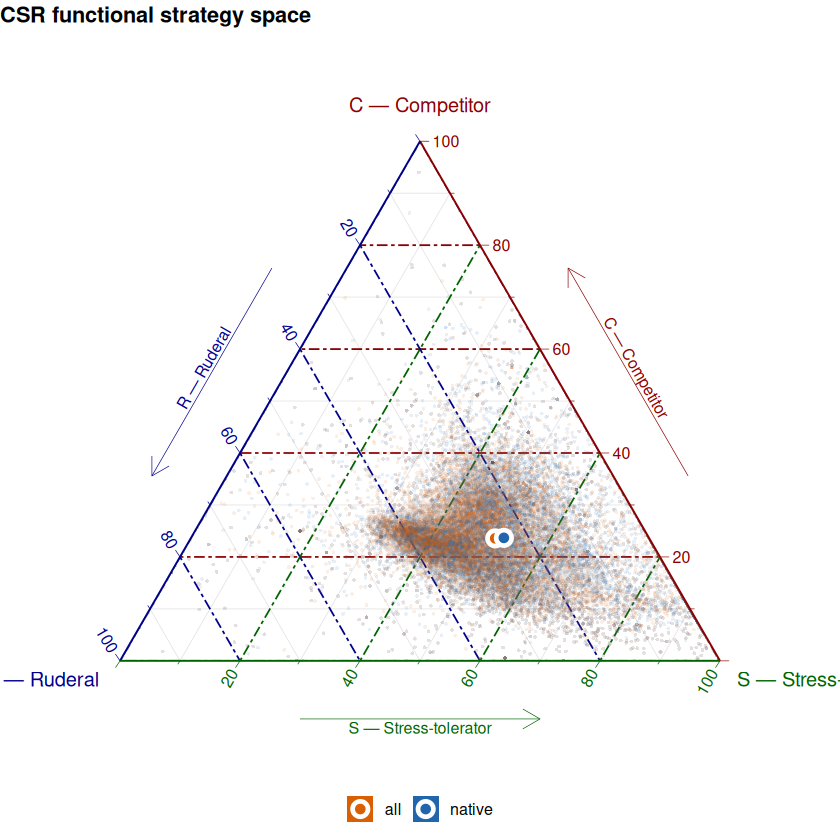

In [ ]:
install.packages("ggtern")  # if needed
library(ggtern)
library(ggplot2)

# Group means for the centroid markers
group_means <- gbif_group[!is.na(C),
                           .(C = mean(C), S = mean(S), R = mean(R)),
                           by = group]

# CVD-friendly two-colour pair
cols <- c(native = "#2166AC", all = "#D95F02")

# In ggtern: aes(x=) → left corner, aes(y=) → top, aes(z=) → right
# Mapping: R bottom-left, C top, S bottom-right  (standard CSR layout)
ggtern(data    = gbif_group[!is.na(C)],
       mapping = aes(x = R, y = C, z = S, colour = group)) +

  # Density contours per group (shows the bulk of the distribution)
  stat_density_tern(
    aes(fill = group, alpha = after_stat(level)),
    geom   = "polygon",
    colour = NA,
    bins   = 7
  ) +

  # Individual pixels (very transparent — gives a sense of spread)
  geom_point(alpha = 0.1, size = 0.7, shape = 16) +

  # Group centroids as bold filled circles
  geom_point(data   = group_means,
             aes(x = R, y = C, z = S, fill = group),
             shape  = 21,
             size   = 3,
             colour = "white",
             stroke = 2) +

  scale_colour_manual(values = cols, name = NULL) +
  scale_fill_manual(  values = cols, name = NULL) +
  scale_alpha_continuous(range = c(0.05, 0.35), guide = "none") +

  # Axis labels at the three corners
  labs(title = "CSR functional strategy space",
       x     = "R — Ruderal",
       y     = "C — Competitor",
       z     = "S — Stress-tolerator") +

  theme_rgbw() +
  theme_showarrows() +
  theme(
    legend.position      = "bottom",
    legend.key           = element_blank(),
    plot.title           = element_text(face = "bold", size = 13),
    tern.axis.title.size = 0.9
  )

ggsave("csr_triangle.pdf", width = 6, height = 6)